# Demo pipeline

**Nota:** En este pipeline se asume que un dataset crudo ya se encuentra subido en HANA

In [1]:
import os
from dotenv import load_dotenv
import hana_ml.dataframe as dataframe
from hana_ml.algorithms.pal.preprocessing import IsolationForest
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import time, importlib, ventanas, explicacion, resultados
import clasificacion

## 1. Lectura del archivo

In [2]:
# Load environment variables from .env file
load_dotenv()

HANA_ADDRESS = os.getenv("HANA_ADDRESS")
HANA_PORT = int(os.getenv("HANA_PORT"))
HANA_USER = os.getenv("HANA_USER")
HANA_PASSWORD = os.getenv("HANA_PASSWORD")

conn = dataframe.ConnectionContext(address = HANA_ADDRESS,
                                   port = HANA_PORT,
                                   user = HANA_USER,
                                   password = HANA_PASSWORD
                                   )
conn.connection.isconnected()

True

In [3]:
TABLA = 'LOGS_2026_10'
dataset = conn.table(TABLA)

## 2. Preparación de los datos

In [4]:
cols_drop_llm = ['HTTP_STATUS_CODE', 'SERVICE_ID', 'CLIENT_IP']

cols_drop_system = [
    'LLM_ERROR_MESSAGE', 'LLM_RESPONSE_SIZE_BYTES', 'SAP_LLM_RESPONSE_SIZE',
    'SAP_LLM_RESPONSE_TIME', 'LLM_PROMPT_TOKENS', 'LLM_COMPLETION_TOKENS',
    'LLM_TOTAL_TOKENS', 'LLM_RESPONSE_TIME_MS', 'LLM_MODEL_ID', 'LLM_STATUS',
    'LLM_COST_USD', 'LLM_PROMPT_CATEGORY', 'LLM_TEMPERATURE', 'LLM_TOP_P',
    'LLM_STREAM', 'LLM_FINISH_REASON', 'LLM_PROMPT_ID', 'LLM_PROVIDER', 'LLM_PROMPT',
]

dataset = dataset.drop(['_IGNORED'])

df_llm = dataset.filter("\"_INDEX\" LIKE 'llm-logs%'").drop(cols_drop_llm)
df_system = dataset.filter("\"_INDEX\" LIKE 'sap-logs%'").drop(cols_drop_system)

print(len(df_llm.columns), len(df_system.columns))

40 24


In [5]:
WEEK_DAYS = 7
MIN_LAST_DAYS = 3   # un sobrante de menos de 3 días se pega a la semana anterior (no se descarta)

TS_EXPR = ("TO_TIMESTAMP(REPLACE(REPLACE(\"TIMESTAMP\",'T',' '),'Z',''), "
           "'YYYY-MM-DD HH24:MI:SS.FF3')")

# t0 y t_max sobre la tabla completa (antes de separar), para que system y llm compartan semanas
r = conn.sql(f'SELECT MIN({TS_EXPR}) AS T0, MAX({TS_EXPR}) AS TMAX FROM {TABLA}').collect()
t0, t_max = pd.to_datetime(r.loc[0, 'T0']), pd.to_datetime(r.loc[0, 'TMAX'])

span = t_max - t0
n_full = span // pd.Timedelta(days=WEEK_DAYS)
rest = span - n_full * pd.Timedelta(days=WEEK_DAYS)
n_weeks = max(1, n_full + (1 if rest >= pd.Timedelta(days=MIN_LAST_DAYS) else 0))

# LEAST manda el sobrante corto (y el último log) a la última semana
t0_sql = t0.strftime('%Y-%m-%d %H:%M:%S')
week_expr = (f"LEAST(FLOOR(SECONDS_BETWEEN(TO_TIMESTAMP('{t0_sql}','YYYY-MM-DD HH24:MI:SS'), "
             f"{TS_EXPR}) / {WEEK_DAYS * 86400}), {n_weeks - 1})")

def add_week(df):
    return df.select('*', (week_expr, 'WEEK_IDX'))

df_system = add_week(df_system)
df_llm = add_week(df_llm)

system_weeks = {w: df_system.filter(f'WEEK_IDX = {w}') for w in range(n_weeks)}
llm_weeks = {w: df_llm.filter(f'WEEK_IDX = {w}') for w in range(n_weeks)}

# Fechas absolutas de cada semana: llave entre datasets y mes de la tabla de resultados
inicios = [t0 + w * pd.Timedelta(days=WEEK_DAYS) for w in range(n_weeks)]
SEMANAS = pd.DataFrame({'WEEK': range(n_weeks), 'WEEK_START': inicios, 'WEEK_END': inicios[1:] + [t_max]})
SEMANAS['DIAS_CUBIERTOS'] = ((SEMANAS['WEEK_END'] - SEMANAS['WEEK_START']).dt.total_seconds() / 86400).round(2)

print(f't0={t0}  t_max={t_max}  n_weeks={n_weeks}')
display(SEMANAS)
print('system:', {w: d.count() for w, d in system_weeks.items()})
print('llm:   ', {w: d.count() for w, d in llm_weeks.items()})

t0=2026-10-01 00:00:00  t_max=2026-10-11 23:59:59  n_weeks=2


,WEEK,WEEK_START,WEEK_END,DIAS_CUBIERTOS
0,0,2026-10-01,2026-10-08 00:00:00,7.0
1,1,2026-10-08,2026-10-11 23:59:59,4.0


system: {0: 1441821, 1: 809290}
llm:    {0: 959153, 1: 538547}


## 3. Generación de ventanas

In [6]:
importlib.reload(ventanas)

SIZES = ventanas.WINDOW_SIZES_S

def prepare_week(w):
    """Eventos base de la semana w, compartidos por todos los tamaños."""
    ventanas.prepare_system_base(conn, system_weeks[w])
    ventanas.prepare_llm_base(conn, llm_weeks[w])

def make_windows(size_s):
    """Ventanas system y LLM de size_s para la semana ya preparada, como temporales con WINDOW_INDEX."""
    win_sys = ventanas.materialize(conn, ventanas.build_system_windows(conn, size_s), '#WIN_SYSTEM')
    win_llm = ventanas.materialize(conn, ventanas.build_llm_windows(conn, size_s), '#WIN_LLM')
    return win_sys, win_llm

## 4. Isolation Forest

In [7]:
FEATURES_SYSTEM = [
    'TOTAL_REQUESTS', 'REQUEST_RATE_STD', 'INTERVAL_CV',
    'UNIQUE_IPS_COUNT', 'IP_ENTROPY', 'IP_TOP_SHARE',
    'ERROR_RATE_400', 'ERROR_RATE_500', 'NON_200_RATE',
    'RATIO_ERROR', 'RATIO_WARN', 'RATIO_SECURITY', 'RATIO_INFO', 'RATIO_AUDIT',
    'GET_VS_POST_RATIO',
    'JS_HTTP_STATUS_CODE', 'JS_HEADERS_HTTP_REQUEST_METHOD', 'JS_SAP_FUNCTION_LOG_TYPE',
    'JS_HEATHERS_REQUEST_PATH', 'JS_SAP_FUNCTION_APPLICATION', 'JS_SAP_SOURCE_TYPE',
    'JS_SAP_APP_ENV', 'JS_REGION_CODE', 'JS_HEADERS_CONTENT_TYPE',
]
FEATURES_LLM = [
    'TOTAL_LLM_REQUESTS', 'AVG_LLM_COST_USD', 'INJECTION_COUNT', 'SAFETY_POLICY_COUNT', 'AUTH_FAILURE_COUNT', 'ACCESS_DENIED_COUNT', 'RATE_ABUSE_COUNT', 'DUPLICATE_REQUEST_COUNT', 'MALFORMED_INPUT_COUNT', 
    'AVG_TOKEN_RATIO', 'AVG_RESPONSE_TIME_MS', 'LLM_ERROR_RATE', 'LLM_TIMEOUT_RATE', 'TEMPERATURE_VARIANCE',
    'PROMPT_CATEGORY_ENTROPY', 'STREAM_RATIO', 'AVG_PROMPT_LENGTH', 'MAX_PROMPT_LENGTH',
]

importlib.reload(explicacion)

def run_if(win, features):
    n = win.count()
    # con pocas ventanas (3 h) max_samples no puede pasar del total
    model = IsolationForest(n_estimators=250, max_samples=min(256, n), random_state=42)
    model.fit(data=win, key='WINDOW_INDEX', features=features)
    pred = model.predict(data=win, key='WINDOW_INDEX', features=features,
                         contamination=0.01, show_explainer=False)
    win_pdf = win.collect()
    r = win_pdf.merge(pred.collect(), on='WINDOW_INDEX')              # ventana + SCORE + LABEL
    an = r[r['LABEL'] == -1]
    idx = an['WINDOW_INDEX'].tolist()
    cf = explicacion.contrafactual(conn, model, win, features,
                                   an.set_index('WINDOW_INDEX')['SCORE'], idx)
    z = explicacion.zscores(win_pdf, idx, features)
    return r, cf, z

STREAMS = ('system', 'llm')
crudo = {s: {st: {'r': [], 'cf': [], 'z': []} for st in STREAMS} for s in SIZES}

for w in range(n_weeks):
    prepare_week(w)                                   # una vez por semana, compartido por los tamaños
    for size_s in SIZES:
        t = time.perf_counter()
        win_sys, win_llm = make_windows(size_s)
        for stream, win, feats in (('system', win_sys, FEATURES_SYSTEM), ('llm', win_llm, FEATURES_LLM)):
            r, cf, z = run_if(win, feats)
            for df, name in ((r, 'r'), (cf, 'cf'), (z, 'z')):
                df.insert(0, 'WEEK', w)
                crudo[size_s][stream][name].append(df)
        print(f'semana {w} | {ventanas.size_label(size_s)} | {round(time.perf_counter() - t)} s')

R = {s: {st: {'if': pd.concat(crudo[s][st]['r'], ignore_index=True),
              'cf': pd.concat(crudo[s][st]['cf'], ignore_index=True),
              'z': pd.concat(crudo[s][st]['z'], ignore_index=True)} for st in STREAMS} for s in SIZES}

semana 0 | 5min | 40 s
semana 0 | 15min | 27 s
semana 0 | 30min | 25 s
semana 0 | 1h | 21 s
semana 0 | 3h | 21 s
semana 1 | 5min | 17 s
semana 1 | 15min | 16 s
semana 1 | 30min | 17 s
semana 1 | 1h | 16 s
semana 1 | 3h | 16 s


In [8]:
MAX_GAP = {s: {'system': 3, 'llm': 3} for s in SIZES}   # en ventanas consecutivas; con traslape del 50 %, 3 pasos = 1.5 tamaños

def agrupar_eventos(res, max_gap):
    """Marca EVENTO_ID: anomalías separadas por <= max_gap ventanas forman un evento. No cruza semanas."""
    res = res.sort_values(['WEEK', 'WINDOW_INDEX']).reset_index(drop=True)
    a = res[res['LABEL'] == -1]
    gap = a.groupby('WEEK')['WINDOW_INDEX'].diff()
    res['EVENTO_ID'] = pd.NA
    res.loc[a.index, 'EVENTO_ID'] = ((gap.isna()) | (gap > max_gap)).cumsum()
    return res

def resumen_eventos(res):
    """Una fila por evento: inicio, fin, nº de ventanas y ventana pico (mayor SCORE de anomalía)."""
    cols = ['EVENTO_ID', 'INICIO', 'FIN', 'N_VENTANAS', 'WEEK', 'VENTANA_PICO', 'SCORE_PICO']
    a = res[res['LABEL'] == -1]
    if a.empty:
        return pd.DataFrame(columns=cols)
    # En PAL el score más alto suele ser más anómalo; se confirma comparando medias.
    alto_es_anomalo = a['SCORE'].mean() >= res.loc[res['LABEL'] != -1, 'SCORE'].mean()
    pick = a.groupby('EVENTO_ID')['SCORE'].idxmax() if alto_es_anomalo else a.groupby('EVENTO_ID')['SCORE'].idxmin()
    pico = (a.loc[pick, ['EVENTO_ID', 'WEEK', 'WINDOW_START', 'SCORE']]
            .rename(columns={'WINDOW_START': 'VENTANA_PICO', 'SCORE': 'SCORE_PICO'})
            .set_index('EVENTO_ID'))
    g = a.groupby('EVENTO_ID').agg(INICIO=('WINDOW_START', 'min'), FIN=('WINDOW_START', 'max'),
                                   N_VENTANAS=('WINDOW_INDEX', 'size'))
    return g.join(pico).reset_index()[cols]

for s in SIZES:
    for st in STREAMS:
        d = R[s][st]
        d['if'] = agrupar_eventos(d['if'], MAX_GAP[s][st])
        d['ev'] = resumen_eventos(d['if'])

def resumen_corrida():
    return pd.DataFrame([{'tamaño': ventanas.size_label(s), 'stream': st, 'ventanas': len(R[s][st]['if']),
                          'anomalías': int((R[s][st]['if']['LABEL'] == -1).sum()),
                          'eventos': len(R[s][st]['ev'])} for s in SIZES for st in STREAMS])

display(resumen_corrida())

,tamaño,stream,ventanas,anomalías,eventos
0,5min,system,6334,65,14
1,5min,llm,6334,65,60
2,15min,system,2110,22,7
3,15min,llm,2110,22,21
4,30min,system,1054,11,6
5,30min,llm,1054,11,11
6,1h,system,526,6,3
7,1h,llm,526,6,6
8,3h,system,174,3,2
9,3h,llm,174,3,3


In [9]:
for s in SIZES:
    for st in STREAMS:
        d = R[s][st]
        if d['ev'].empty:
            continue
        d['if'] = d['if'].merge(explicacion.dominantes_por_ventana(d['cf'], d['z']),
                                on=['WEEK', 'WINDOW_INDEX'], how='left')
        d['ev'] = d['ev'].merge(explicacion.explicar_eventos(d['if'], d['cf'], d['z']),
                                on='EVENTO_ID', how='left')

In [10]:
Z_UMBRAL = {s: 5 for s in SIZES}   # |z| máximo que debe alcanzar un evento; uno por tamaño (ver la tabla de sensibilidad)
VER = 300                          # tamaño que se grafica e inspecciona en las celdas siguientes

def marcar_relevantes(if_df, z, eventos, umbral):
    """Añade a la tabla de eventos Z_MAX, Z_MAX_FEATURE y RELEVANTE (Z_MAX >= umbral)."""
    zz = z.merge(if_df.loc[if_df['LABEL'] == -1, ['WEEK', 'WINDOW_INDEX', 'EVENTO_ID']],
                 on=['WEEK', 'WINDOW_INDEX'])
    zz['ZABS'] = zz['Z'].abs()
    pico = zz.loc[zz.groupby('EVENTO_ID')['ZABS'].idxmax(), ['EVENTO_ID', 'FEATURE', 'ZABS']]
    pico = pico.rename(columns={'FEATURE': 'Z_MAX_FEATURE', 'ZABS': 'Z_MAX'})
    out = eventos.drop(columns=['Z_MAX', 'Z_MAX_FEATURE', 'RELEVANTE'], errors='ignore') \
                 .merge(pico, on='EVENTO_ID', how='left')
    out['RELEVANTE'] = out['Z_MAX'] >= umbral
    return out

# Dataset para el clustering multiclase: ventanas anómalas de eventos relevantes,
# solo con las columnas de la ventana (sin SCORE, LABEL, EVENTO_ID ni explicaciones).
POST_IF = {'SCORE', 'LABEL', 'EVENTO_ID', 'WINDOW_INDEX'}

def dataset_multiclase(if_df, eventos):
    post = POST_IF | {c for c in if_df.columns if c.startswith(('CF_', 'Z_'))}
    rel = eventos.loc[eventos['RELEVANTE'], 'EVENTO_ID']
    a = if_df[(if_df['LABEL'] == -1) & if_df['EVENTO_ID'].isin(rel)]
    ds = a[[c for c in if_df.columns if c not in post]].reset_index(drop=True)
    mapa = a[['WEEK', 'WINDOW_START', 'EVENTO_ID']].reset_index(drop=True)   # para volver al evento
    return ds, mapa

for s in SIZES:
    for st in STREAMS:
        d = R[s][st]
        d['ev'] = marcar_relevantes(d['if'], d['z'], d['ev'], Z_UMBRAL[s])
        d['ds'], d['mapa'] = dataset_multiclase(d['if'], d['ev'])

resumen = resumen_corrida()
resumen['relevantes'] = [int(R[s][st]['ev']['RELEVANTE'].sum()) for s in SIZES for st in STREAMS]
resumen['ventanas_relevantes'] = [len(R[s][st]['ds']) for s in SIZES for st in STREAMS]
resumen['umbral_z'] = [Z_UMBRAL[s] for s in SIZES for st in STREAMS]
display(resumen)

# Sensibilidad: cuántos eventos quedarían como relevantes con cada umbral, por tamaño y stream
UMBRALES = (3, 4, 5, 6, 8, 10)
display(pd.DataFrame([{'tamaño': ventanas.size_label(s), 'stream': st,
                       **{f'>= {u}': int((R[s][st]['ev']['Z_MAX'] >= u).sum()) for u in UMBRALES}}
                      for s in SIZES for st in STREAMS]))

cols = ['EVENTO_ID', 'WEEK', 'INICIO', 'N_VENTANAS', 'SCORE_PICO', 'Z_MAX', 'Z_MAX_FEATURE', 'RELEVANTE']
for st in STREAMS:
    print(f'{st} ({ventanas.size_label(VER)}): eventos con mayor Z_MAX')
    display(R[VER][st]['ev'].sort_values('Z_MAX', ascending=False)[cols].head(15))

,tamaño,stream,ventanas,anomalías,eventos,relevantes,ventanas_relevantes,umbral_z
0,5min,system,6334,65,14,7,57,5
1,5min,llm,6334,65,60,0,0,5
2,15min,system,2110,22,7,7,22,5
3,15min,llm,2110,22,21,0,0,5
4,30min,system,1054,11,6,5,10,5
5,30min,llm,1054,11,11,0,0,5
6,1h,system,526,6,3,3,6,5
7,1h,llm,526,6,6,0,0,5
8,3h,system,174,3,2,2,3,5
9,3h,llm,174,3,3,0,0,5


,tamaño,stream,>= 3,>= 4,>= 5,>= 6,>= 8,>= 10
0,5min,system,11,8,7,7,7,7
1,5min,llm,43,11,0,0,0,0
2,15min,system,7,7,7,7,7,4
3,15min,llm,5,1,0,0,0,0
4,30min,system,6,6,5,5,5,4
5,30min,llm,5,0,0,0,0,0
6,1h,system,3,3,3,3,3,3
7,1h,llm,0,0,0,0,0,0
8,3h,system,2,2,2,1,1,0
9,3h,llm,0,0,0,0,0,0


system (5min): eventos con mayor Z_MAX


,EVENTO_ID,WEEK,INICIO,N_VENTANAS,SCORE_PICO,Z_MAX,Z_MAX_FEATURE,RELEVANTE
12,13,1,2026-10-10 02:40:00,6,0.804415,26.562422,JS_HEADERS_HTTP_REQUEST_METHOD,True
2,3,0,2026-10-01 12:42:30,7,0.790703,25.163175,JS_SAP_FUNCTION_APPLICATION,True
3,4,0,2026-10-01 23:47:30,8,0.704218,24.767299,UNIQUE_IPS_COUNT,True
9,10,0,2026-10-05 13:02:30,14,0.808383,21.792049,JS_SAP_SOURCE_TYPE,True
10,11,1,2026-10-09 09:17:30,8,0.656800,15.941580,UNIQUE_IPS_COUNT,True
1,2,0,2026-10-01 09:30:00,5,0.759521,13.373361,JS_SAP_FUNCTION_APPLICATION,True
11,12,1,2026-10-09 10:00:00,9,0.617499,10.121822,UNIQUE_IPS_COUNT,True
4,5,0,2026-10-03 03:52:30,1,0.531256,4.168963,JS_HEADERS_CONTENT_TYPE,False
5,6,0,2026-10-04 10:20:00,2,0.529673,3.349757,RATIO_AUDIT,False
0,1,0,2026-10-01 07:57:30,1,0.544224,3.175626,JS_SAP_SOURCE_TYPE,False


llm (5min): eventos con mayor Z_MAX


,EVENTO_ID,WEEK,INICIO,N_VENTANAS,SCORE_PICO,Z_MAX,Z_MAX_FEATURE,RELEVANTE
52,53,1,2026-10-10 05:25:00,1,0.566847,4.912129,SAFETY_POLICY_COUNT,False
0,1,0,2026-10-01 05:52:30,1,0.528209,4.351844,DUPLICATE_REQUEST_COUNT,False
27,28,0,2026-10-06 02:47:30,2,0.539050,4.351844,DUPLICATE_REQUEST_COUNT,False
24,25,0,2026-10-05 07:00:00,1,0.540213,4.351844,DUPLICATE_REQUEST_COUNT,False
22,23,0,2026-10-04 21:47:30,2,0.526210,4.351844,DUPLICATE_REQUEST_COUNT,False
17,18,0,2026-10-03 20:12:30,1,0.523265,4.351844,DUPLICATE_REQUEST_COUNT,False
15,16,0,2026-10-03 13:50:00,1,0.522688,4.341821,INJECTION_COUNT,False
4,5,0,2026-10-02 02:35:00,1,0.523195,4.341821,INJECTION_COUNT,False
14,15,0,2026-10-03 12:27:30,1,0.531110,4.341821,INJECTION_COUNT,False
49,50,1,2026-10-09 20:57:30,1,0.525165,4.074474,AVG_TOKEN_RATIO,False


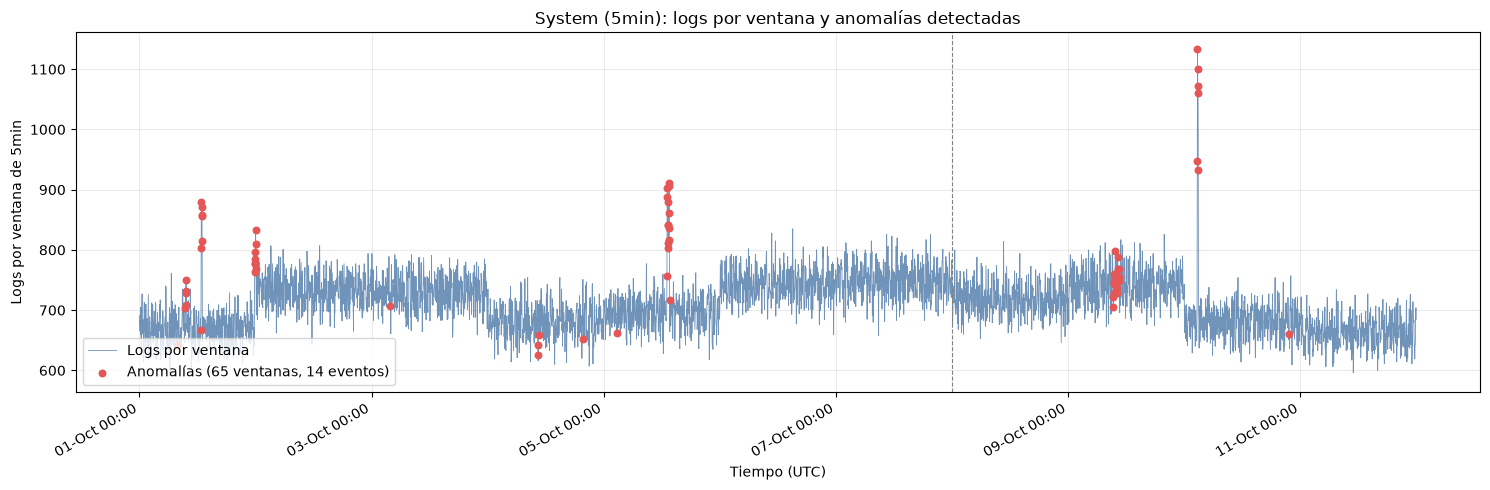

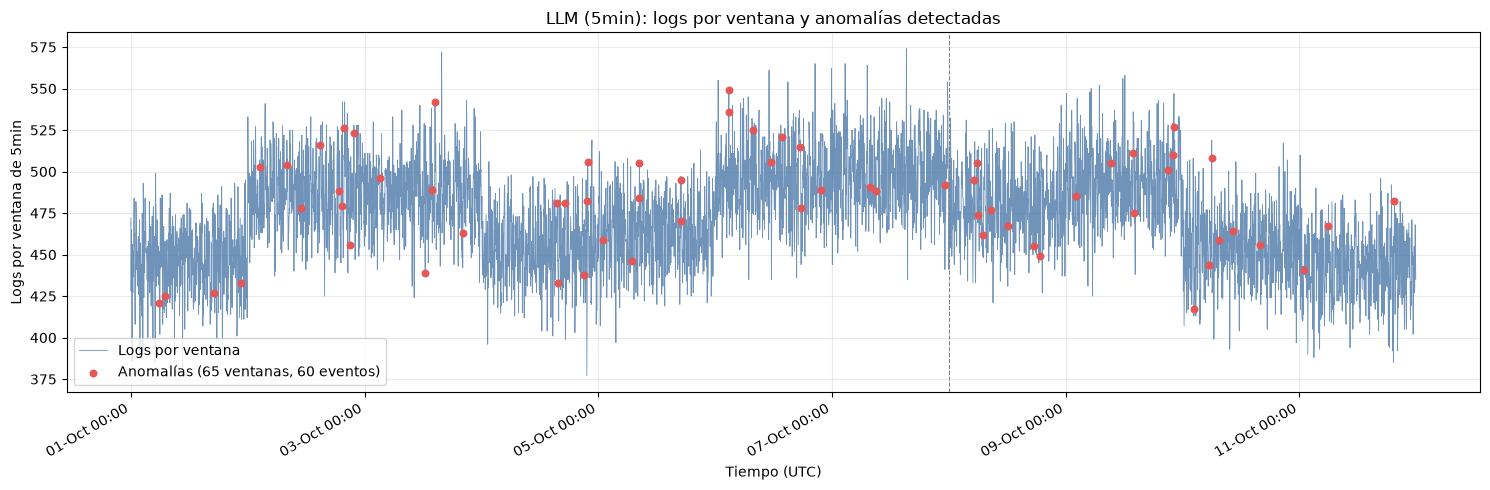

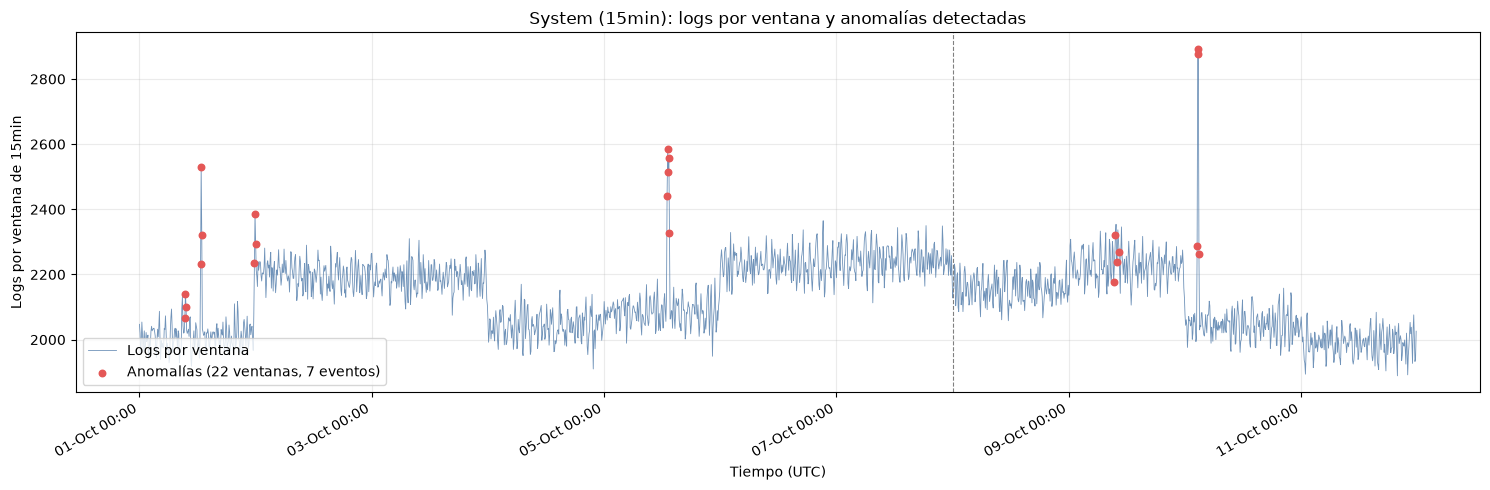

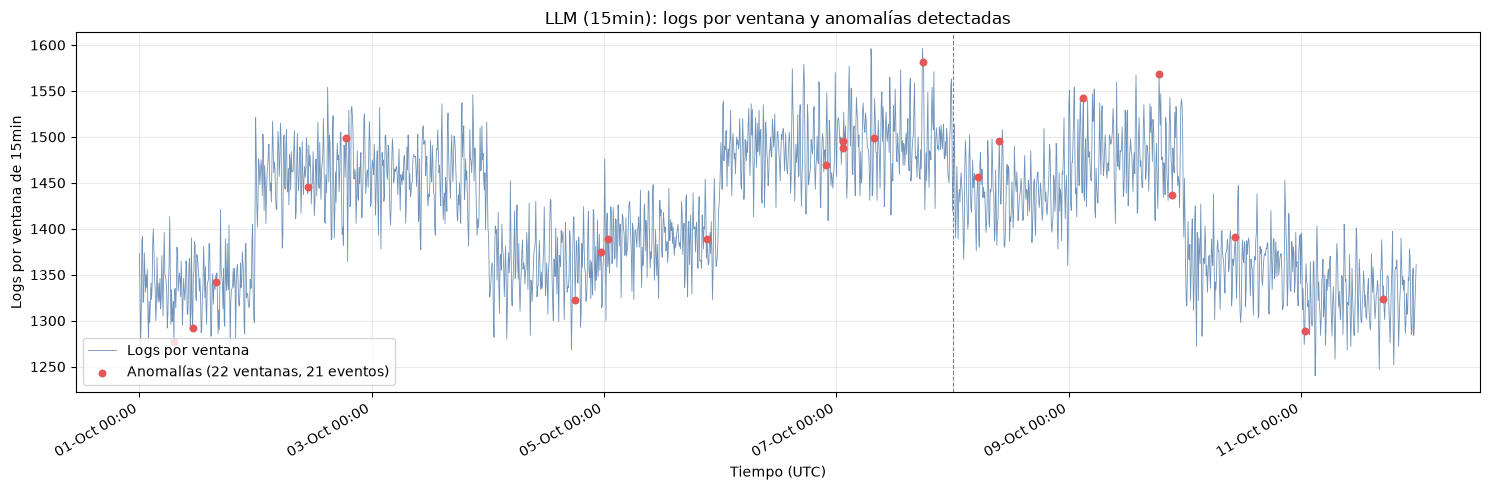

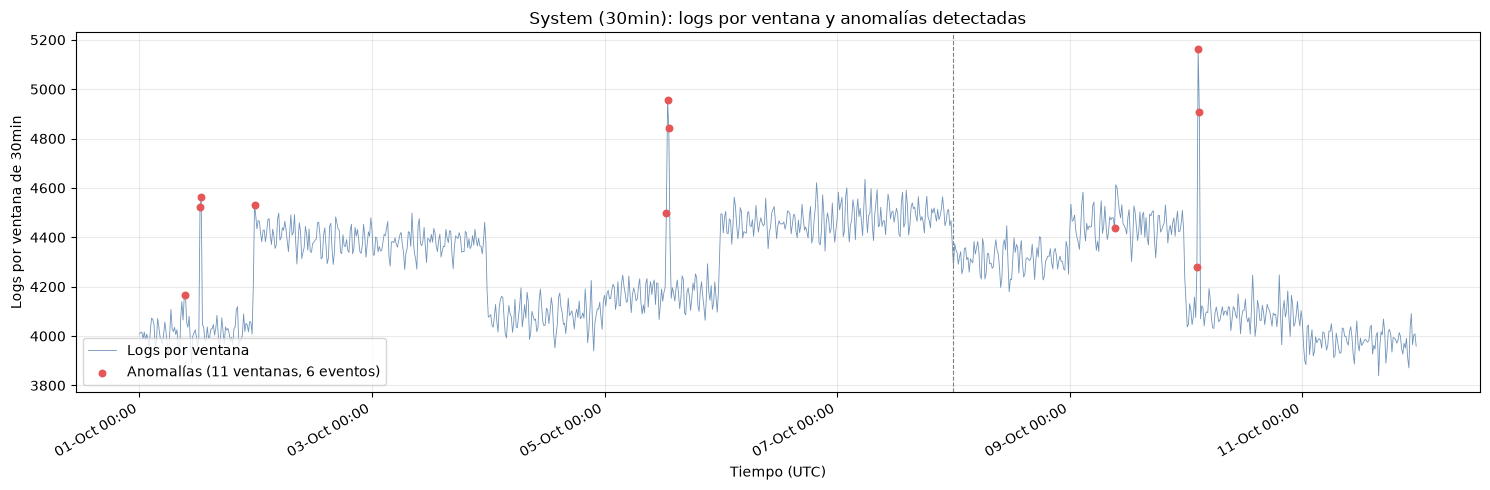

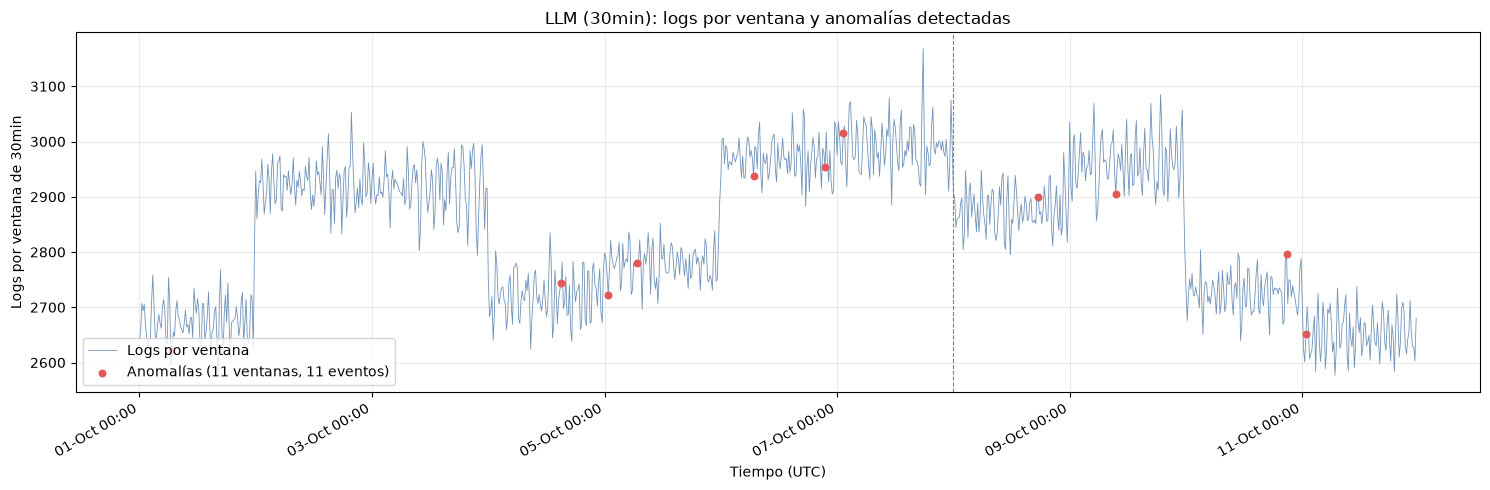

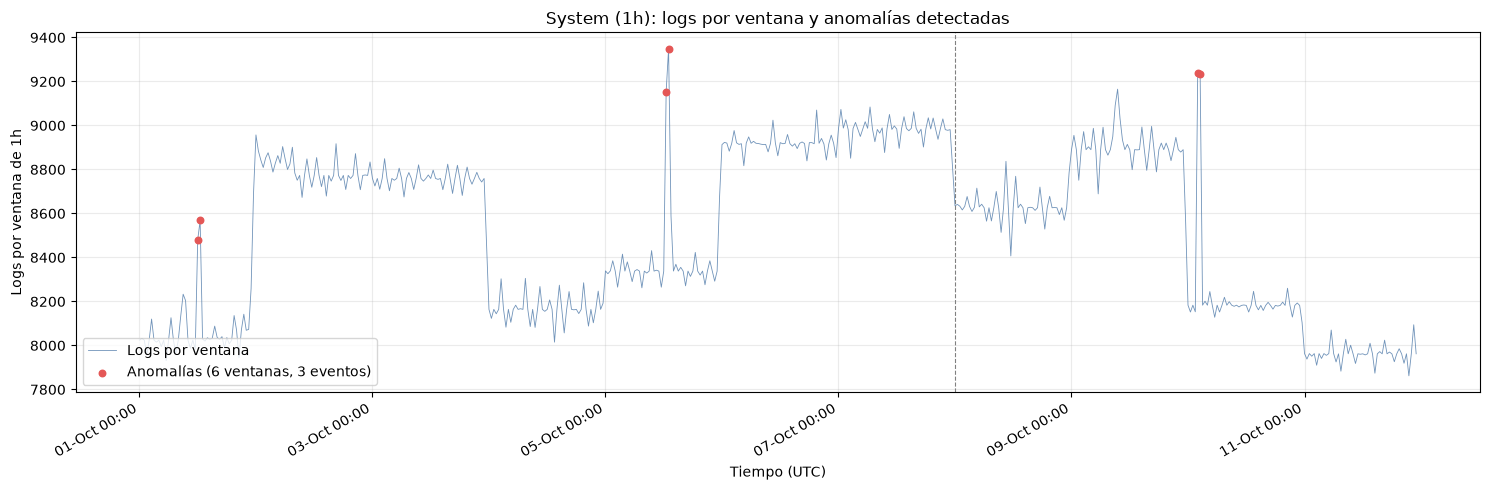

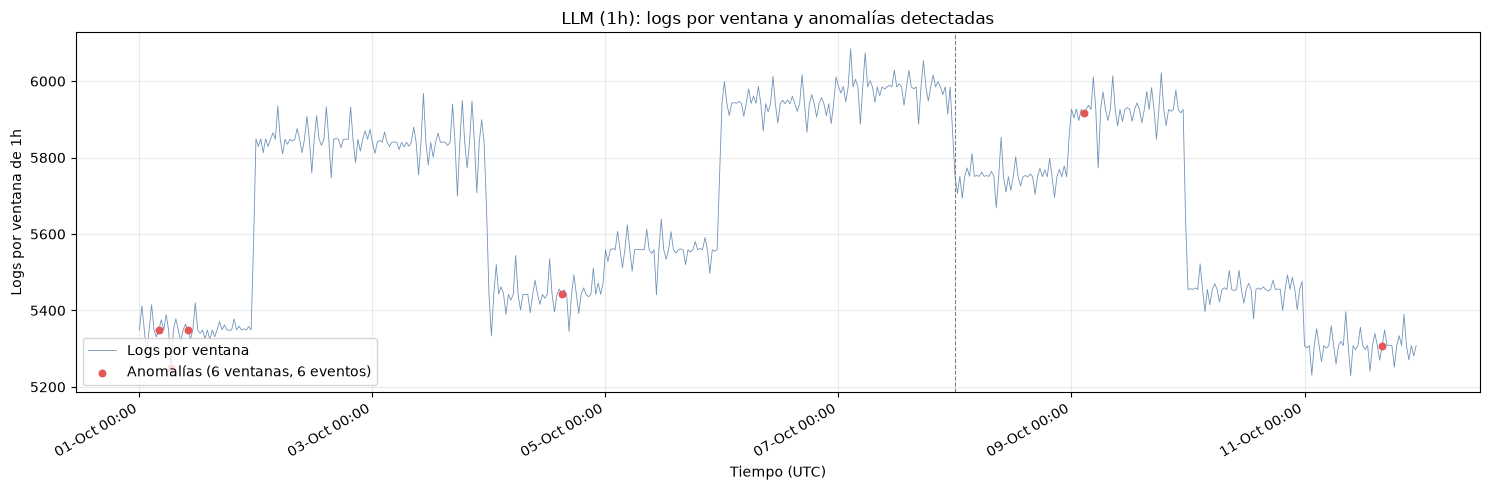

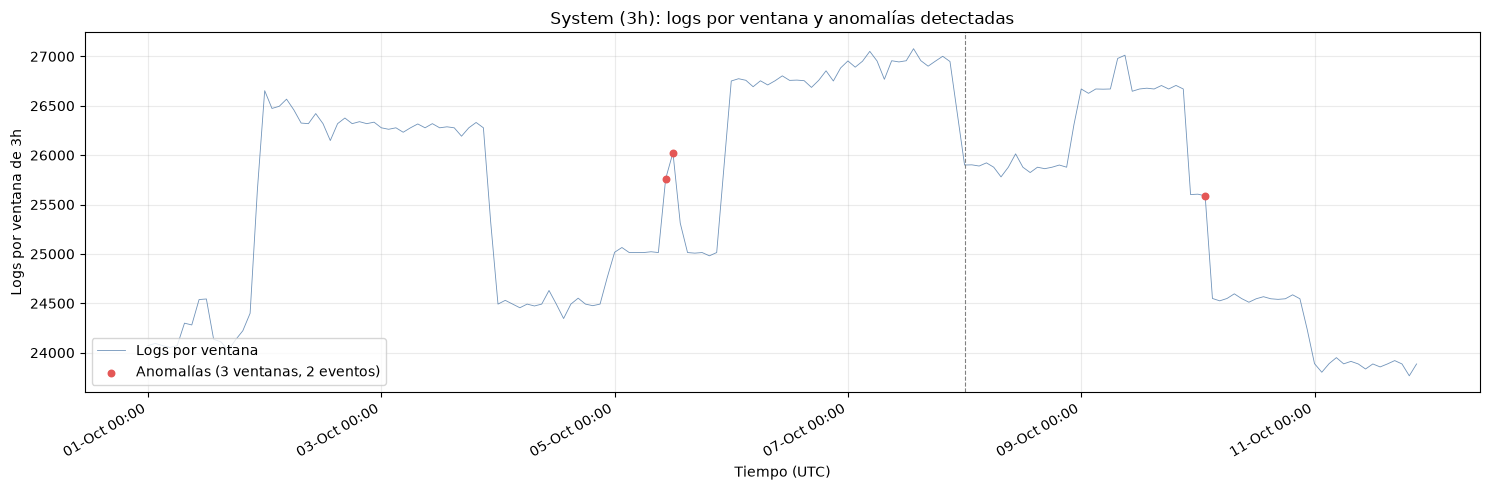

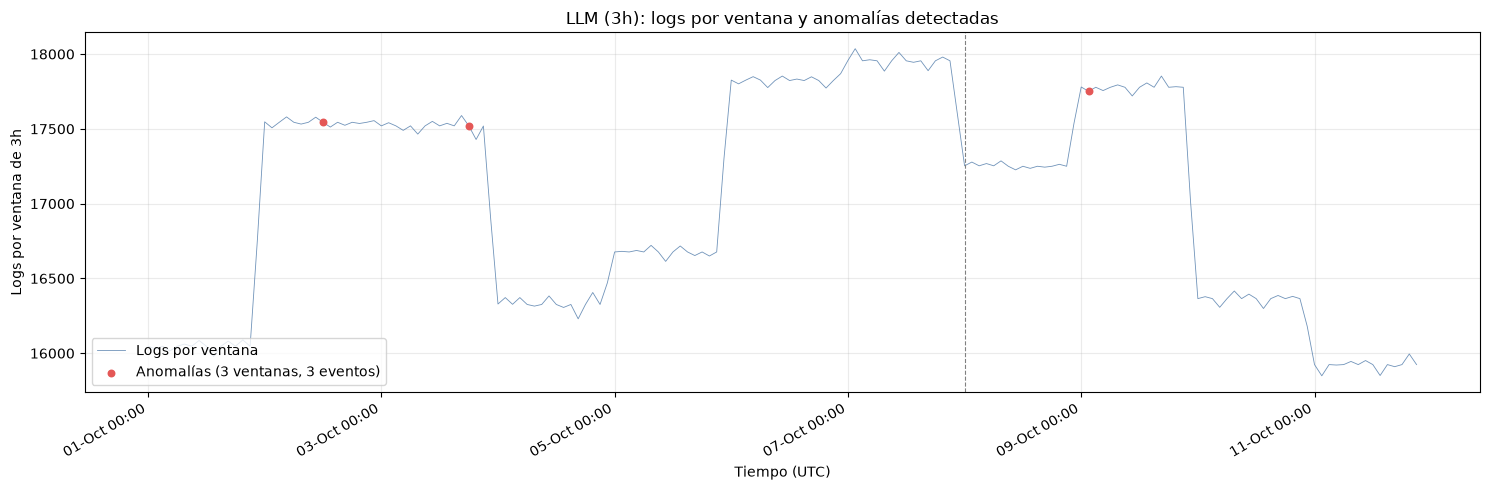

In [11]:
def graficar(res, col, titulo, size_s):
    d = res.sort_values('WINDOW_START')
    a = d[d['LABEL'] == -1]
    fig, ax = plt.subplots(figsize=(15, 5))
    ax.plot(d['WINDOW_START'], d[col], color='#4c78a8', lw=0.6, alpha=0.8, label='Logs por ventana')
    ax.scatter(a['WINDOW_START'], a[col], color='#e45756', s=22, zorder=3,
               label=f"Anomalías ({len(a)} ventanas, {a['EVENTO_ID'].nunique()} eventos)")
    for w, g in d.groupby('WEEK'):
        if w > 0:
            ax.axvline(g['WINDOW_START'].min(), color='gray', ls='--', lw=0.8)   # corte de semana
    ax.set_title(titulo)
    ax.set_xlabel('Tiempo (UTC)')
    ax.set_ylabel(f'Logs por ventana de {ventanas.size_label(size_s)}')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d-%b %H:%M'))
    ax.grid(alpha=0.25)
    ax.legend(loc='lower left')
    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()

for size_s in SIZES:
    for st, col, nombre in (('system', 'TOTAL_REQUESTS', 'System'), ('llm', 'TOTAL_LLM_REQUESTS', 'LLM')):
        d = R[size_s][st]
        graficar(d['if'], col, f'{nombre} ({ventanas.size_label(size_s)}): logs por ventana y anomalías detectadas', size_s)

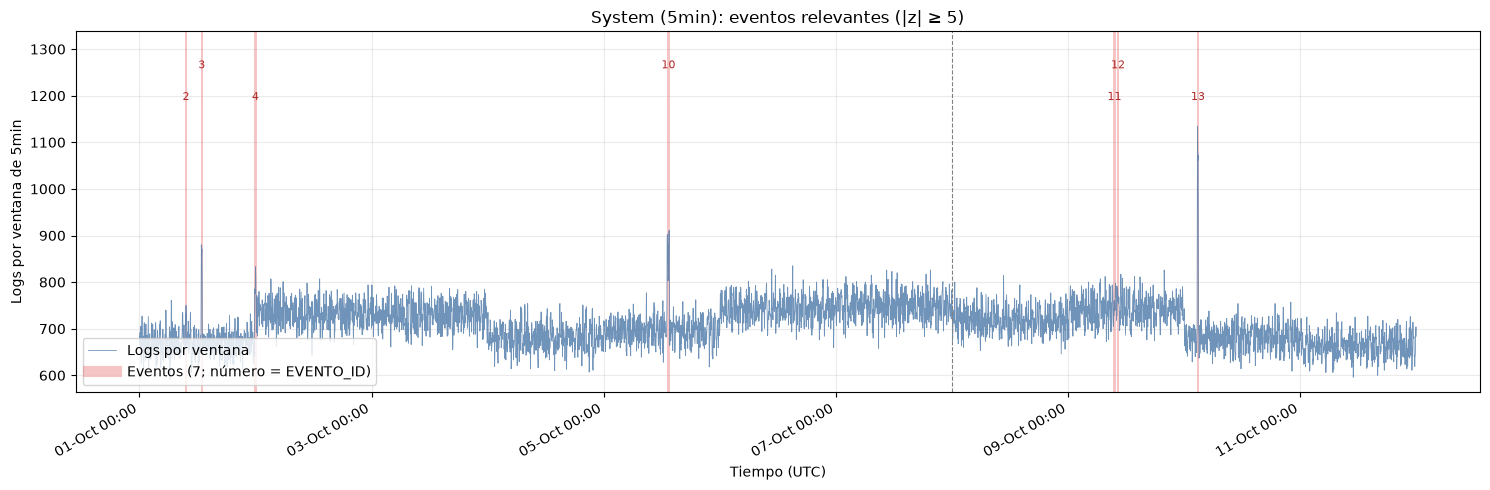

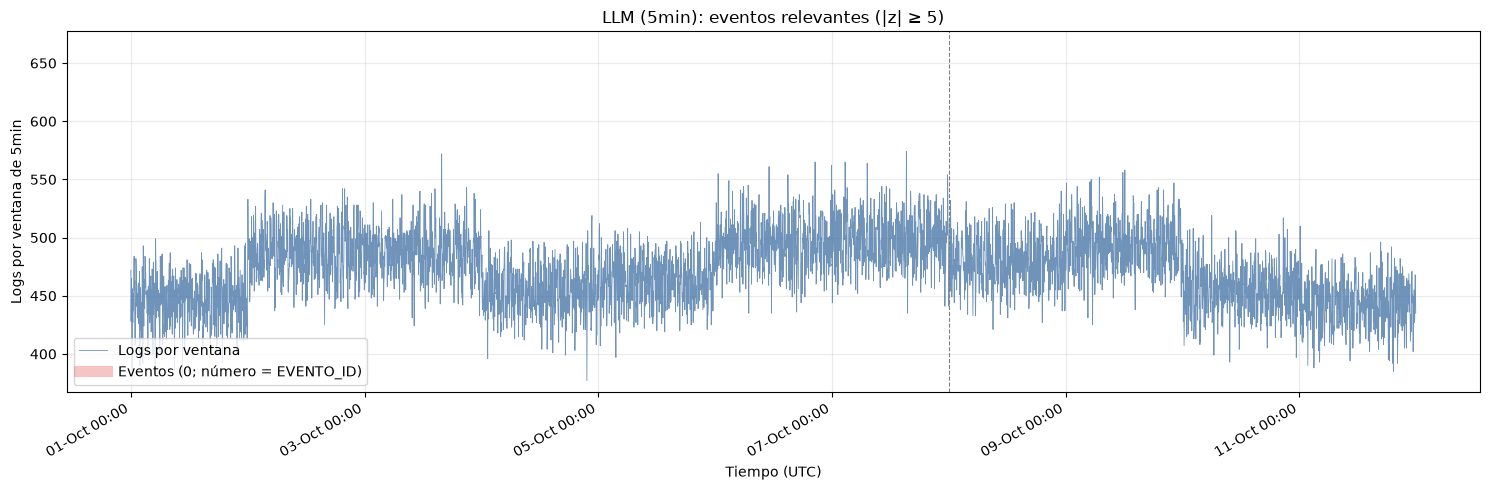

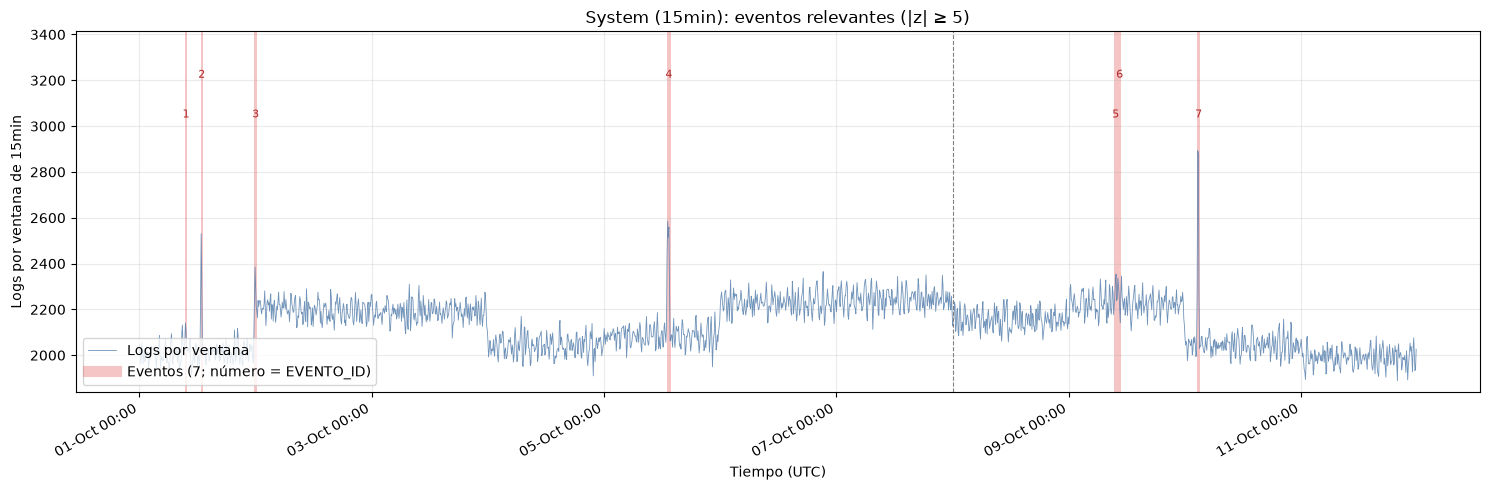

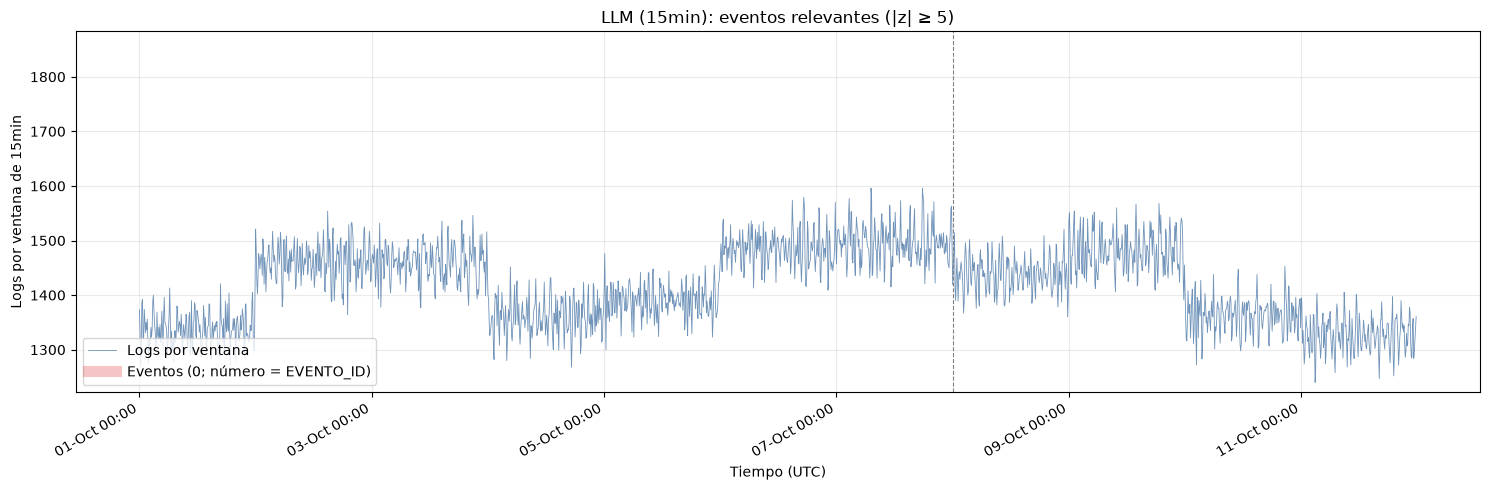

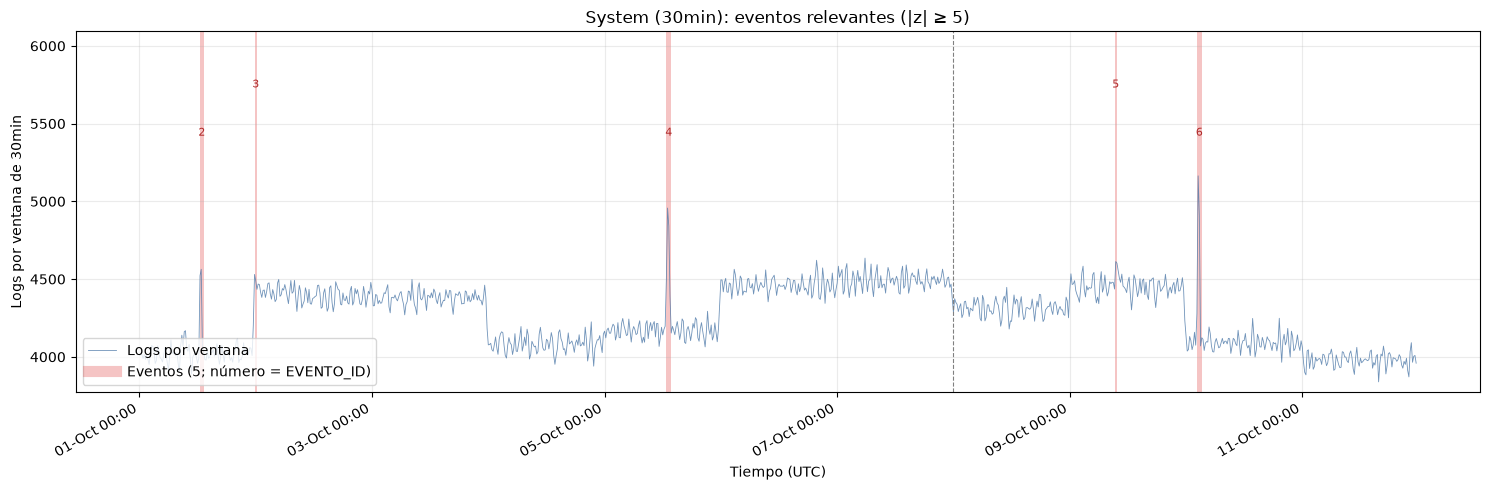

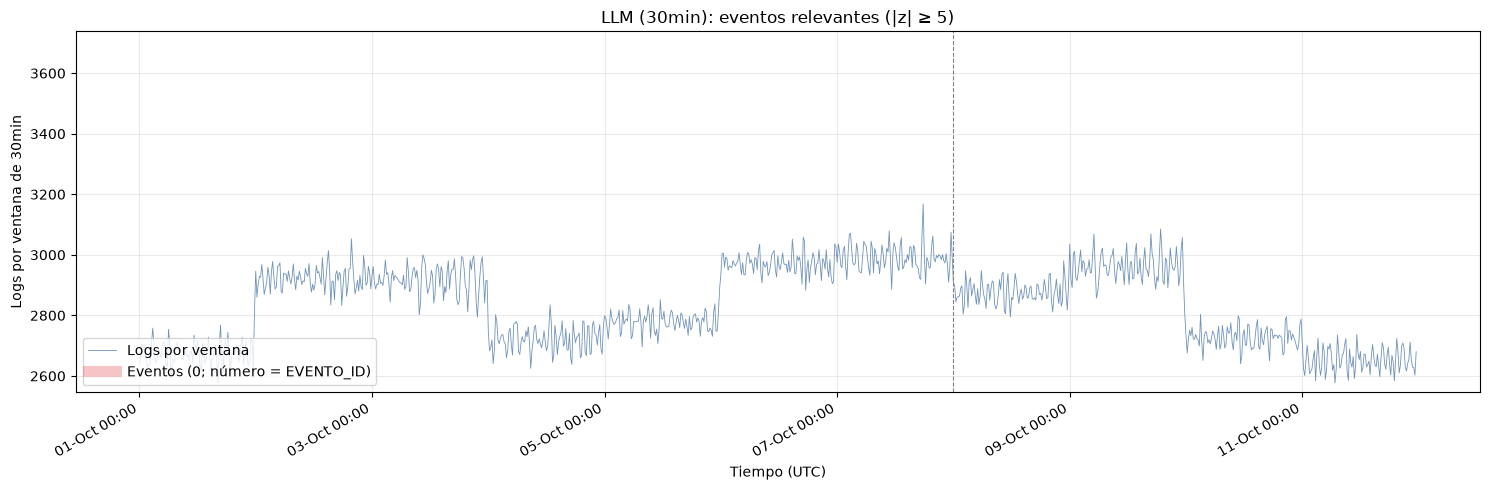

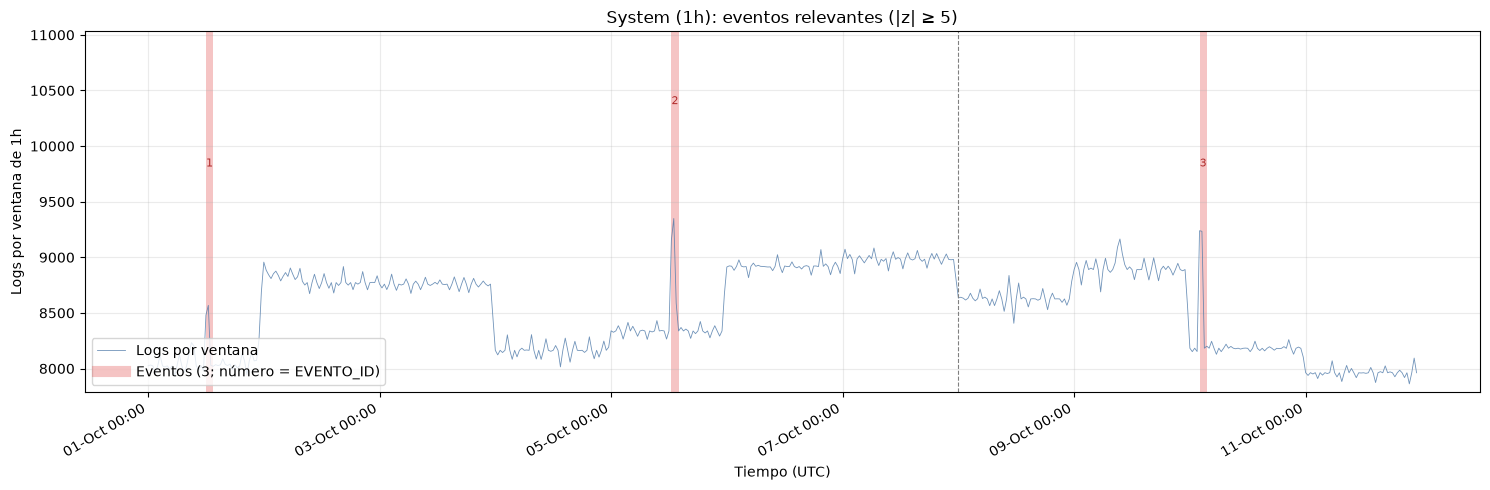

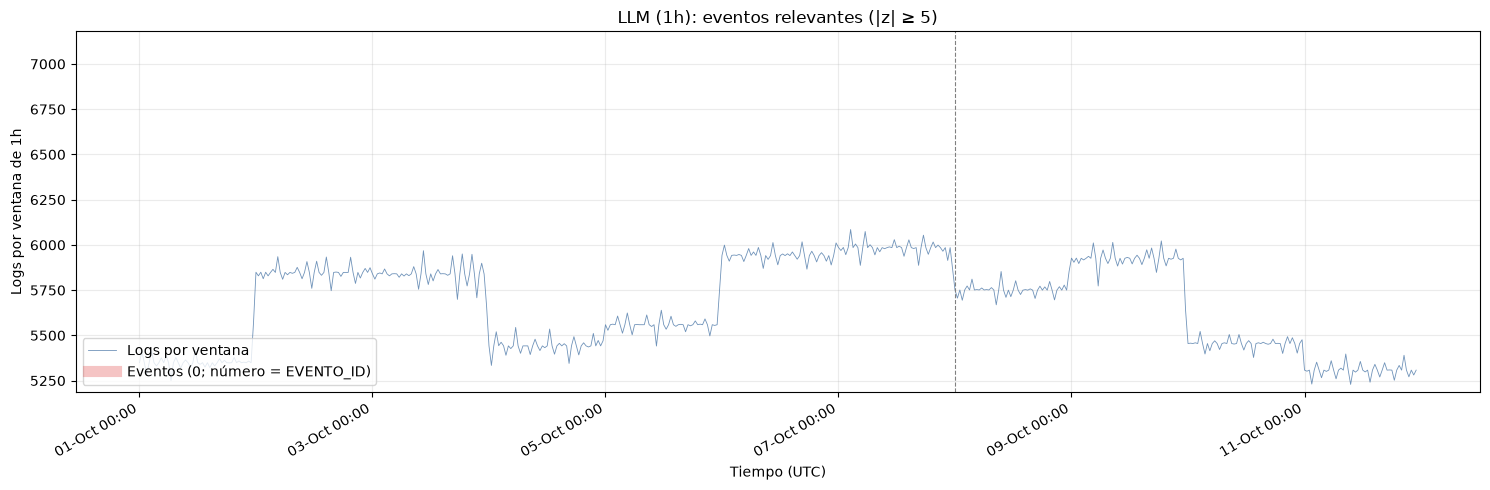

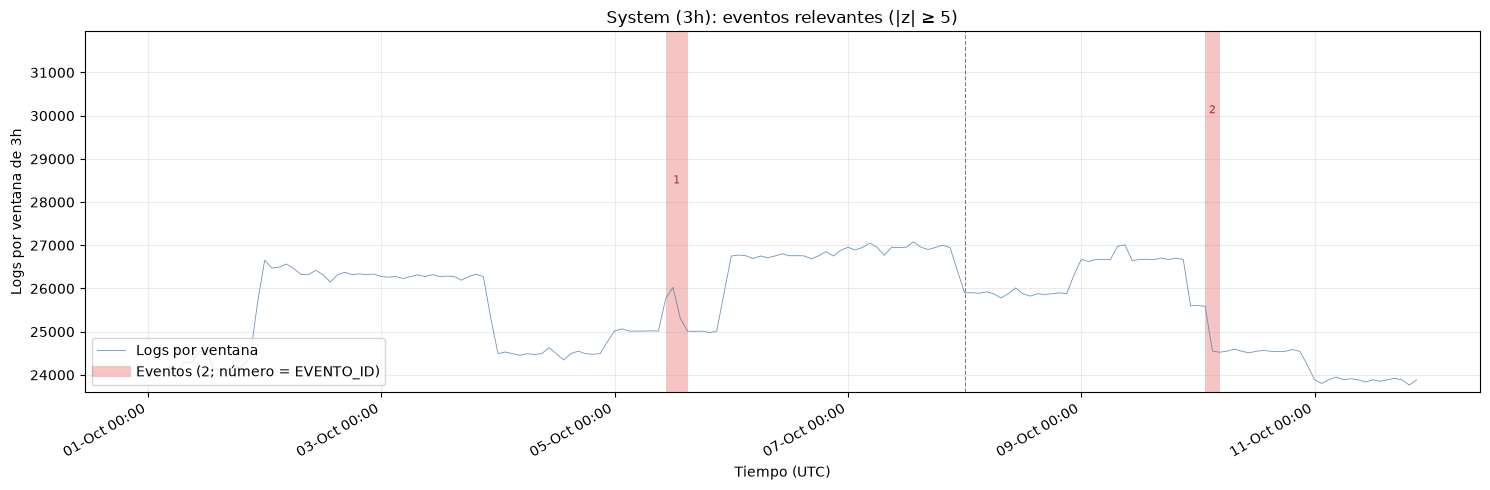

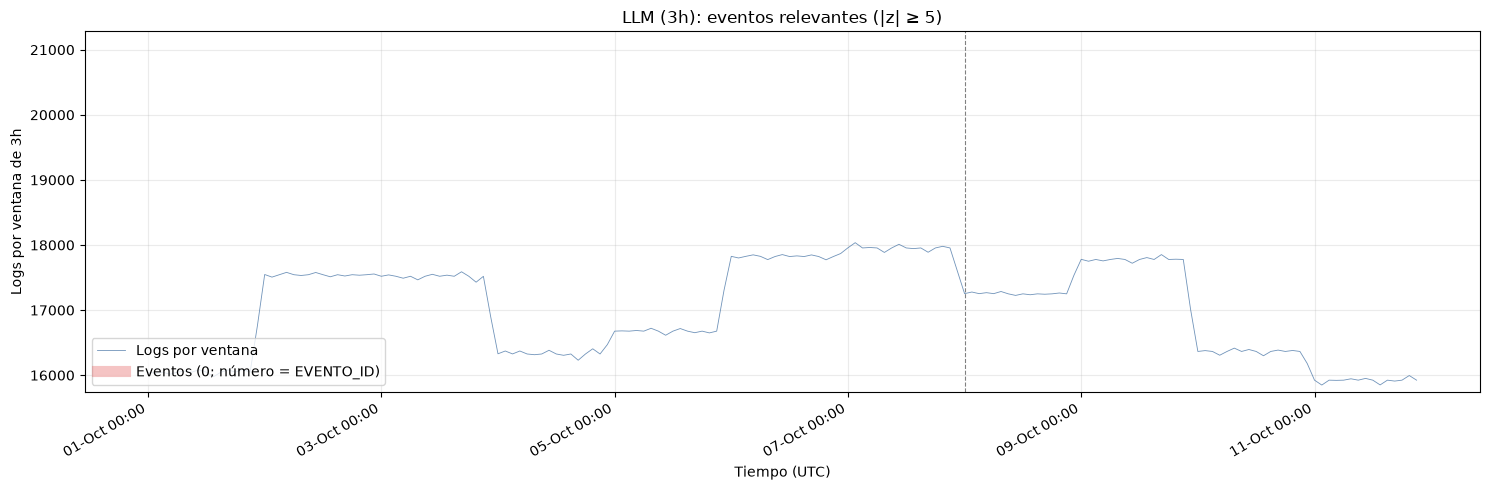

In [12]:
def graficar_eventos(res, eventos, col, titulo, size_s, solo_relevantes=True, ancho_min_min=30):
    d = res.sort_values('WINDOW_START')
    ev = eventos[eventos['RELEVANTE']] if solo_relevantes else eventos
    fig, ax = plt.subplots(figsize=(15, 5))
    ax.plot(d['WINDOW_START'], d[col], color='#4c78a8', lw=0.6, alpha=0.8, label='Logs por ventana')
    for w, g in d.groupby('WEEK'):
        if w > 0:
            ax.axvline(g['WINDOW_START'].min(), color='gray', ls='--', lw=0.8)   # corte de semana

    ymax = d[col].max()
    ax.set_ylim(top=ymax * 1.18)
    for k, e in enumerate(ev.sort_values('INICIO').itertuples()):
        ini = e.INICIO
        fin = e.FIN + pd.Timedelta(seconds=size_s)                    # una ventana dura 5 min
        mid = ini + (fin - ini) / 2
        piso = pd.Timedelta(minutes=ancho_min_min)                 # ancho mínimo para que se vea
        if fin - ini < piso:
            ini, fin = mid - piso / 2, mid + piso / 2
        ax.axvspan(ini, fin, color='#e45756', alpha=0.35, lw=0)
        ax.text(mid, ymax * (1.05 if k % 2 == 0 else 1.11), str(e.EVENTO_ID),
                ha='center', fontsize=8, color='#b02a2a')          # alterna alturas para no encimar
    ax.plot([], [], color='#e45756', alpha=0.35, lw=8,
            label=f'Eventos ({len(ev)}; número = EVENTO_ID)')

    ax.set_title(titulo)
    ax.set_xlabel('Tiempo (UTC)')
    ax.set_ylabel(f'Logs por ventana de {ventanas.size_label(size_s)}')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d-%b %H:%M'))
    ax.grid(alpha=0.25)
    ax.legend(loc='lower left')
    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()

for size_s in SIZES:
    for st, col, nombre in (('system', 'TOTAL_REQUESTS', 'System'), ('llm', 'TOTAL_LLM_REQUESTS', 'LLM')):
        d = R[size_s][st]
        graficar_eventos(d['if'], d['ev'], col,
                         f'{nombre} ({ventanas.size_label(size_s)}): eventos relevantes (|z| ≥ {Z_UMBRAL[size_s]})', size_s)

,EVENTO_ID,WEEK,INICIO,FIN,N_VENTANAS,SCORE_PICO,Z_MAX,Volumen y ritmo,Origen (IPs),Tipo de log,Respuestas HTTP,Peticiones,Contexto SAP,TOP_FEATURES
6,13,1,2026-10-10 02:40:00,2026-10-10 02:52:30,6,0.804415,26.562422,5.31,12.43,7.71,10.22,11.99,13.30,"IP_TOP_SHARE (+18.9), JS_HTTP_STATUS_CODE (+18.3), JS_SAP_APP_ENV (+18.0)"
1,3,0,2026-10-01 12:42:30,2026-10-01 12:57:30,7,0.790703,25.163175,1.96,7.31,5.59,5.71,5.97,10.14,"JS_SAP_FUNCTION_LOG_TYPE (+14.5), JS_SAP_FUNCTION_APPLICATION (+14.4), JS_HEATHERS_REQ..."
2,4,0,2026-10-01 23:47:30,2026-10-02 00:05:00,8,0.704218,24.767299,1.44,8.74,2.03,2.40,0.81,3.95,"UNIQUE_IPS_COUNT (+21.6), JS_SAP_FUNCTION_APPLICATION (+5.9), ERROR_RATE_500 (+4.3)"
3,10,0,2026-10-05 13:02:30,2026-10-05 13:35:00,14,0.808383,21.792049,2.10,8.03,3.95,6.36,7.59,8.20,"IP_TOP_SHARE (+12.4), JS_HTTP_STATUS_CODE (+11.6), JS_SAP_APP_ENV (+11.5)"
4,11,1,2026-10-09 09:17:30,2026-10-09 09:45:00,8,0.656800,15.941580,0.91,3.77,0.88,0.83,0.96,0.77,"UNIQUE_IPS_COUNT (+9.7), JS_HEATHERS_REQUEST_PATH (+1.8), ERROR_RATE_400 (+1.7)"
0,2,0,2026-10-01 09:30:00,2026-10-01 09:40:00,5,0.759521,13.373361,0.54,4.93,2.52,4.33,4.02,6.26,"JS_SAP_FUNCTION_APPLICATION (+8.6), IP_TOP_SHARE (+8.0), JS_HTTP_STATUS_CODE (+7.5)"
5,12,1,2026-10-09 10:00:00,2026-10-09 10:30:00,9,0.617499,10.121822,1.18,3.17,0.85,0.66,0.89,0.42,"UNIQUE_IPS_COUNT (+8.1), REQUEST_RATE_STD (-1.5), JS_HEATHERS_REQUEST_PATH (+1.3)"


,EVENTO_ID,WEEK,INICIO,FIN,N_VENTANAS,SCORE_PICO,Z_MAX,Volumen y recursos,Fallos,Contenido del prompt,Parámetros de la llamada,Mensajes de seguridad,TOP_FEATURES


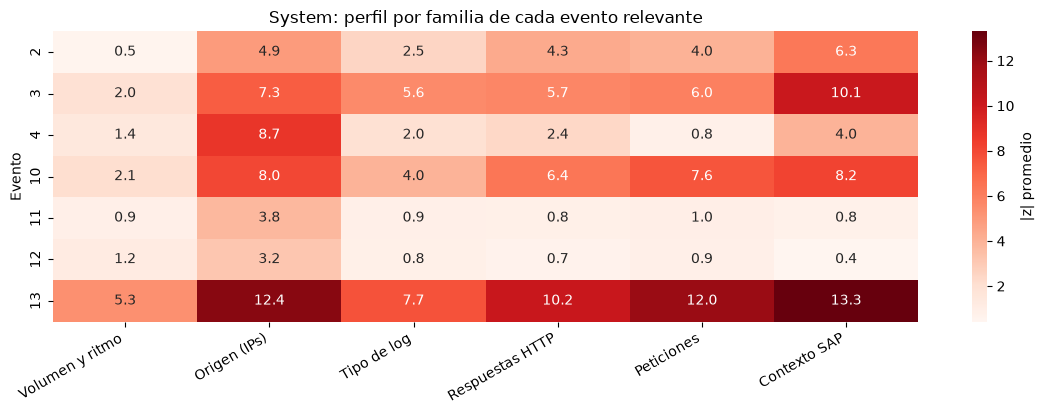

LLM: sin eventos relevantes, no hay mapa de calor.


In [13]:
importlib.reload(explicacion)

base_cols = ['EVENTO_ID', 'WEEK', 'INICIO', 'FIN', 'N_VENTANAS', 'SCORE_PICO', 'Z_MAX']

def perfil_relevantes(eventos, if_df, z, familias):
    """Perfil por familia solo de los eventos relevantes (RELEVANTE = True)."""
    rel = eventos[eventos['RELEVANTE']]
    return rel[base_cols].merge(explicacion.perfil_familias(if_df, z, familias), on='EVENTO_ID')

d_s, d_l = R[VER]['system'], R[VER]['llm']
perfil_system = perfil_relevantes(d_s['ev'], d_s['if'], d_s['z'], explicacion.FAMILIAS_SYSTEM)
perfil_llm = perfil_relevantes(d_l['ev'], d_l['if'], d_l['z'], explicacion.FAMILIAS_LLM)

with pd.option_context('display.width', 250, 'display.max_columns', None, 'display.max_colwidth', 90):
    display(perfil_system.sort_values('Z_MAX', ascending=False))
    display(perfil_llm.sort_values('Z_MAX', ascending=False))

# Mapa de calor: una fila por evento relevante, una columna por familia (|z| promedio)
for nombre, perfil, familias in (('System', perfil_system, explicacion.FAMILIAS_SYSTEM),
                                 ('LLM', perfil_llm, explicacion.FAMILIAS_LLM)):
    if perfil.empty:
        print(f'{nombre}: sin eventos relevantes, no hay mapa de calor.')
        continue
    mapa = perfil.set_index('EVENTO_ID')[list(familias)]
    fig, ax = plt.subplots(figsize=(1.6 * len(familias) + 2, 0.32 * len(mapa) + 2))
    sns.heatmap(mapa, annot=True, fmt='.1f', cmap='Reds', cbar_kws={'label': '|z| promedio'}, ax=ax)
    ax.set_title(f'{nombre}: perfil por familia de cada evento relevante')
    ax.set_ylabel('Evento')
    ax.set_xlabel('')
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.show()

In [14]:
CLIP_Z = None   # p. ej. 10 para recortar colas largas; None = sin recorte

def normalizar_por_semana(ds, if_df, features, clip=None):
    """
    Z-score con signo de las `features` de las ventanas de `ds`, con media y desviación de TODAS
    las ventanas de su semana (if_df), no solo de las anómalas. Devuelve solo esas variables,
    en el mismo orden de filas que `ds`. sd = 0 o valor faltante -> z = 0.
    """
    g = if_df.groupby('WEEK')[features]
    mu = g.mean()
    sd = g.std(ddof=0).replace(0, np.nan)
    sem = ds['WEEK'].values
    z = (ds[features].astype(float).values - mu.loc[sem].values) / sd.loc[sem].values
    z = pd.DataFrame(z, columns=features).fillna(0)
    return z.clip(-clip, clip) if clip else z

for s in SIZES:
    for st, feats in (('system', FEATURES_SYSTEM), ('llm', FEATURES_LLM)):
        d = R[s][st]
        d['X'] = normalizar_por_semana(d['ds'], d['if'], feats, CLIP_Z)
        assert len(d['X']) == len(d['ds']) == len(d['mapa']), f'{s} {st}: filas desalineadas'
        assert list(d['X'].columns) == feats, f'{s} {st}: columnas distintas a las del IF'
        assert not d['X'].isna().any().any(), f'{s} {st}: hay NaN'

display(pd.DataFrame([{'tamaño': ventanas.size_label(s), 'stream': st, 'X': R[s][st]['X'].shape,
                       'eventos': R[s][st]['mapa']['EVENTO_ID'].nunique()}
                      for s in SIZES for st in STREAMS]))

,tamaño,stream,X,eventos
0,5min,system,"(57, 24)",7
1,5min,llm,"(0, 18)",0
2,15min,system,"(22, 24)",7
3,15min,llm,"(0, 18)",0
4,30min,system,"(10, 24)",5
5,30min,llm,"(0, 18)",0
6,1h,system,"(6, 24)",3
7,1h,llm,"(0, 18)",0
8,3h,system,"(3, 24)",2
9,3h,llm,"(0, 18)",0


## 5. Separación Multi-Clase

In [15]:
importlib.reload(clasificacion)

clasificacion.validar_firmas(FEATURES_SYSTEM, clasificacion.FIRMAS_SYSTEM)
clasificacion.validar_firmas(FEATURES_LLM, clasificacion.FIRMAS_LLM)

NUEVAS = ['TIPO_ATAQUE', 'MARGEN', 'CONFIANZA', 'SIN_SIGNO', 'TOP3', 'VOTOS']
K_TIPOS = {s: {} for s in SIZES}   # cantidad de tipos identificados, por tamaño y stream

for s in SIZES:
    for st, firmas in (('system', clasificacion.FIRMAS_SYSTEM), ('llm', clasificacion.FIRMAS_LLM)):
        d = R[s][st]
        d['tipos'] = clasificacion.clasificar_eventos(d['if'], d['z'], d['ev'], firmas)
        d['ev'] = d['ev'].drop(columns=NUEVAS, errors='ignore').merge(d['tipos'], on='EVENTO_ID', how='left')
        d['mapa']['TIPO_ATAQUE'] = d['mapa']['EVENTO_ID'].astype(int).map(d['tipos'].set_index('EVENTO_ID')['TIPO_ATAQUE'])
        K_TIPOS[s][st] = clasificacion.resumen_tipos(d['tipos'])

display(pd.DataFrame([{'tamaño': ventanas.size_label(s), 'stream': st, 'tipos': K_TIPOS[s][st]['tipos'],
                       'ataques': K_TIPOS[s][st]['ataques'], 'eventos_por_tipo': K_TIPOS[s][st]['eventos_por_tipo']}
                      for s in SIZES for st in STREAMS]))

,tamaño,stream,tipos,ataques,eventos_por_tipo
0,5min,system,2,2,"{'Contexto SAP': 4, 'DDoS': 3}"
1,5min,llm,0,0,{}
2,15min,system,3,3,"{'DDoS': 3, 'Fuerza bruta': 2, 'Contexto SAP': 2}"
3,15min,llm,0,0,{}
4,30min,system,3,3,"{'Contexto SAP': 2, 'DDoS': 2, 'Fuerza bruta': 1}"
5,30min,llm,0,0,{}
6,1h,system,2,2,"{'Contexto SAP': 2, 'Fuerza bruta': 1}"
7,1h,llm,0,0,{}
8,3h,system,2,2,"{'Fuerza bruta': 1, 'Contexto SAP': 1}"
9,3h,llm,0,0,{}


## 6. Clustering Multi-Clase

In [16]:
import clustering
importlib.reload(clustering)

for s in SIZES:
    for st in STREAMS:
        d = R[s][st]
        d['mapa']['CLUSTER_ID'], d['estados'] = clustering.clusterizar_semanas(conn, d['X'], d['mapa'])

display(pd.concat([R[s][st]['estados'].assign(tamaño=ventanas.size_label(s), stream=st)
                   for s in SIZES for st in STREAMS], ignore_index=True)
        [['tamaño', 'stream', 'WEEK', 'ventanas', 'eventos', 'K', 'estado', 'motivo']])

,tamaño,stream,WEEK,ventanas,eventos,K,estado,motivo
0,5min,system,0,34,4,2,evaluable,
1,5min,system,1,23,3,2,evaluable,
2,15min,system,0,14,4,3,evaluable,
3,15min,system,1,8,3,2,evaluable,
4,30min,system,0,6,3,2,evaluable,
5,30min,system,1,4,2,2,evaluable,
6,1h,system,0,4,2,1,no evaluable,solo 1 tipo(s) en la semana
7,1h,system,1,2,1,1,no evaluable,solo 1 tipo(s) en la semana
8,3h,system,0,2,1,1,no evaluable,solo 1 tipo(s) en la semana
9,3h,system,1,1,1,1,no evaluable,solo 1 tipo(s) en la semana


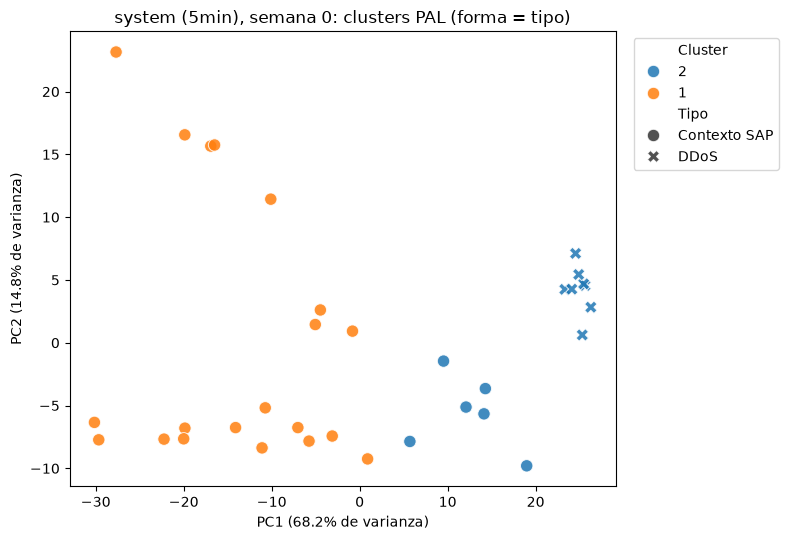

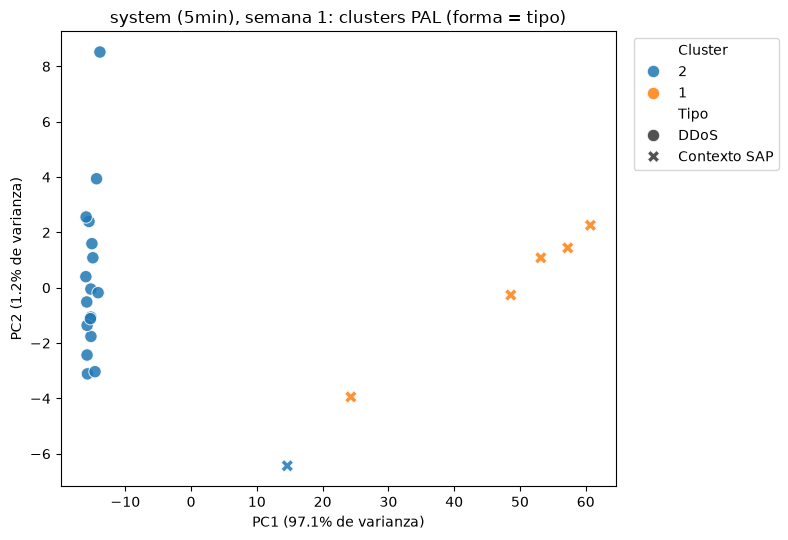

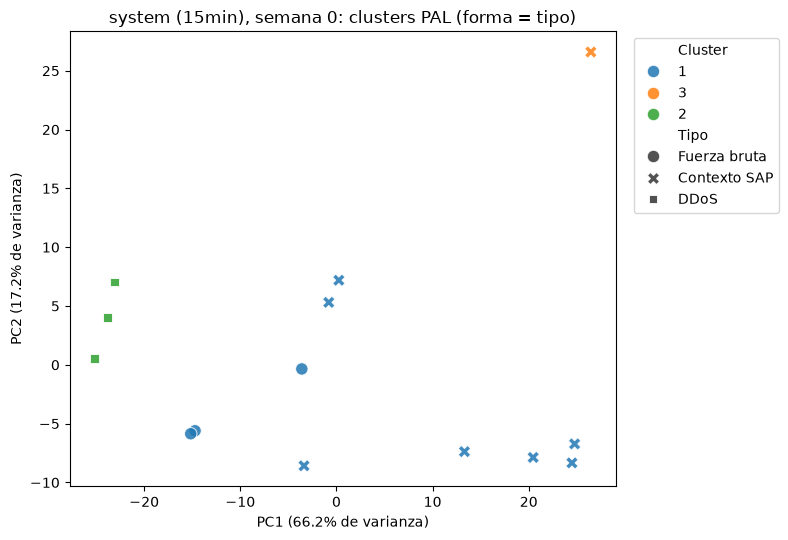

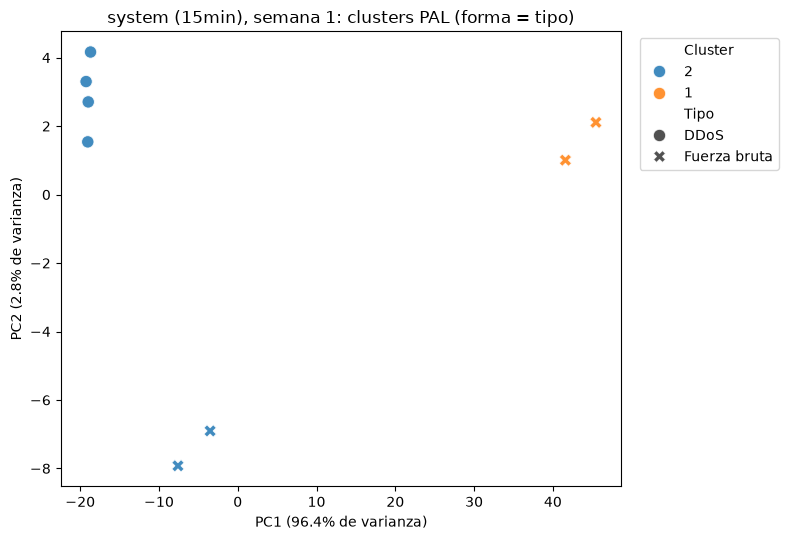

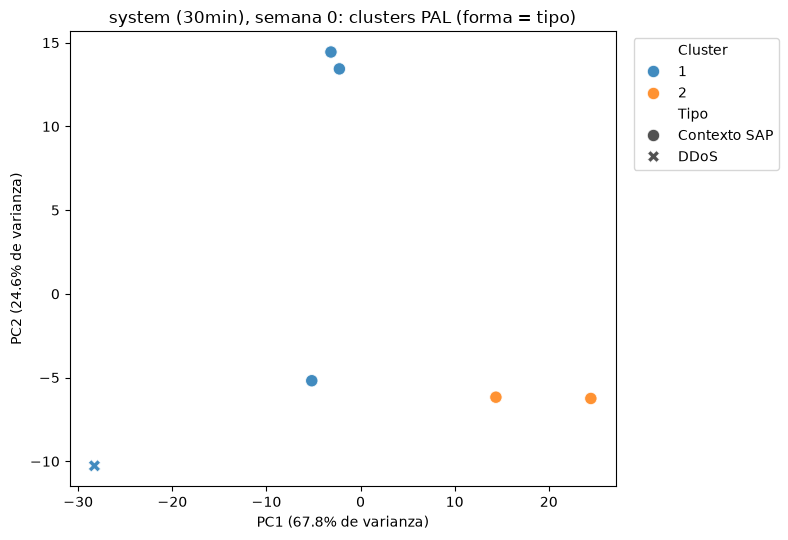

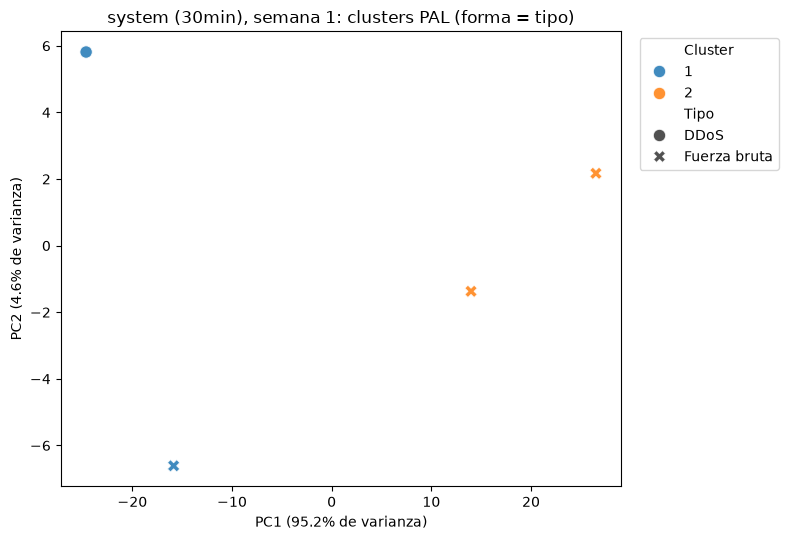

In [17]:
for size_s in (300, 900, 1800):          # a 1 h y 3 h no hay semanas evaluables
    for st in STREAMS:
        d = R[size_s][st]
        for w in d['estados'].loc[d['estados']['estado'] == 'evaluable', 'WEEK']:
            clustering.graficar_pca(d['X'], d['mapa'], w,
                                    f'{st} ({ventanas.size_label(size_s)}), semana {w}: clusters PAL (forma = tipo)')

## 7. Validación Clustering Vs. Separación

In [18]:
validacion = pd.concat([clustering.validar_semanas(R[s][st]['mapa'], R[s][st]['estados'])
                        .assign(tamaño=ventanas.size_label(s), stream=st)
                        for s in SIZES for st in STREAMS], ignore_index=True)

cols = ['tamaño', 'stream', 'WEEK', 'estado', 'K', 'ventanas', 'eventos',
        'ARI', 'NMI', 'homogeneidad', 'completitud', 'ARI_eventos', 'motivo']
display(validacion[cols].round(2))

# Resumen: promedio solo de las semanas evaluables
ev = validacion[validacion['estado'] == 'evaluable']
grupo = ev.groupby(['tamaño', 'stream'], sort=False)
display(grupo[['ARI', 'NMI', 'homogeneidad', 'completitud']].mean().round(2)
        .join(grupo.size().rename('semanas_evaluables')))
print('Semanas no evaluables:', int((validacion['estado'] != 'evaluable').sum()), 'de', len(validacion))

# Tabla cruzada tipo × cluster de las semanas evaluables del tamaño VER
for st in STREAMS:
    d = R[VER][st]
    for w in d['estados'].loc[d['estados']['estado'] == 'evaluable', 'WEEK']:
        print(f'{st} ({ventanas.size_label(VER)}), semana {w}')
        display(clustering.tabla_cruzada(d['mapa'], w))

,tamaño,stream,WEEK,estado,K,ventanas,eventos,ARI,NMI,homogeneidad,completitud,ARI_eventos,motivo
0,5min,system,0,evaluable,2,34,4,0.400793,0.432343,0.484604,0.390257,1.0,
1,5min,system,1,evaluable,2,23,3,0.815793,0.739918,0.707446,0.775514,1.0,
2,15min,system,0,evaluable,3,14,4,0.393044,0.625265,0.554751,0.716317,0.333333,
3,15min,system,1,evaluable,2,8,3,0.16,0.343711,0.311278,0.383689,1.0,
4,30min,system,0,evaluable,2,6,3,-0.173913,0.13922,0.167949,0.118884,-0.5,
5,30min,system,1,evaluable,2,4,2,0.0,0.343711,0.383689,0.311278,NaN,
6,1h,system,0,no evaluable,1,4,2,NaN,NaN,NaN,NaN,NaN,solo 1 tipo(s) en la semana
7,1h,system,1,no evaluable,1,2,1,NaN,NaN,NaN,NaN,NaN,solo 1 tipo(s) en la semana
8,3h,system,0,no evaluable,1,2,1,NaN,NaN,NaN,NaN,NaN,solo 1 tipo(s) en la semana
9,3h,system,1,no evaluable,1,1,1,NaN,NaN,NaN,NaN,NaN,solo 1 tipo(s) en la semana


,,ARI,NMI,homogeneidad,completitud,semanas_evaluables
tamaño,stream,,,,,
5min,system,0.608293,0.58613,0.596025,0.582886,2
15min,system,0.276522,0.484488,0.433014,0.550003,2
30min,system,-0.086957,0.241465,0.275819,0.215081,2


Semanas no evaluables: 4 de 10
system (5min), semana 0


CLUSTER_ID,1,2,total
TIPO_ATAQUE,,,
Contexto SAP,20,6,26
DDoS,0,8,8
total,20,14,34


system (5min), semana 1


CLUSTER_ID,1,2,total
TIPO_ATAQUE,,,
Contexto SAP,5,1,6
DDoS,0,17,17
total,5,18,23


In [19]:
g = R[300]['system']['mapa']; g = g[g['WEEK'] == 0]
display(pd.crosstab([g['EVENTO_ID'], g['TIPO_ATAQUE']], g['CLUSTER_ID'].astype(int)))

,CLUSTER_ID,1,2
EVENTO_ID,TIPO_ATAQUE,,
2,Contexto SAP,3,2
3,Contexto SAP,5,2
4,DDoS,0,8
10,Contexto SAP,12,2


## 8. Carga de archivos a SAP HANA

In [20]:
importlib.reload(resultados)

RESET = False   # True tira y recrea las tablas de los meses de esta corrida (borra TODOS los datasets cargados en ellas)

tablas = resultados.construir(TABLA, R, SIZES, SEMANAS, Z_UMBRAL, MAX_GAP, validacion)
display(resultados.guardar(conn, tablas, TABLA, reset=RESET))

,tabla,acción,filas,filas_en_HANA,total_en_tabla,ok
0,RESULT_WINDOWS_SYSTEM_2026_10,creada,10198,10198,10198,True
1,RESULT_WINDOWS_LLM_2026_10,creada,10198,10198,10198,True
2,RESULT_EVENTS_2026_10,creada,133,133,133,True
3,RESULT_SUMMARY_2026_10,creada,20,20,20,True
4,RESULT_VALIDATION_2026_10,creada,10,10,10,True
